In [5]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx
import cobra

# Step 1: double check that their original processed data actually,,, works 

Sheet names in workbook: ['E.coli (iJ01366)', 'B. subtilis (iYO844)', 'G. metallireducens (iAF987)', 'K. pneumoniae (iYL1228)', 'S. cerevisiae (iMM904)']


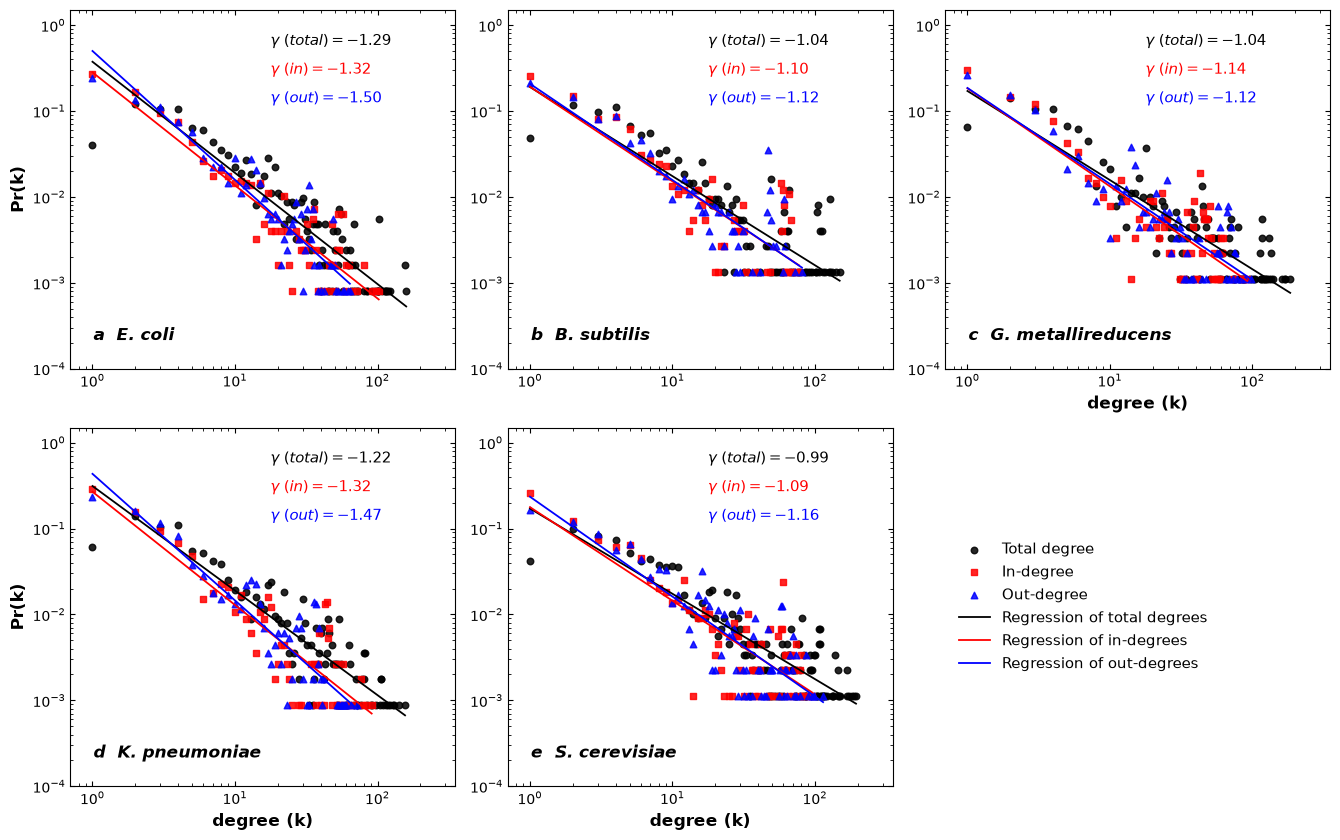

In [6]:

excel_path = "/mnt/c/Users/loren/Downloads/data-20261116T170559Z-1-001/data/12859_2019_2897_MOESM2_ESM.xlsx"
xl = pd.ExcelFile(excel_path)
print("Sheet names in workbook:", xl.sheet_names)
organisms = [
    {"panel": "a", "label": "E. coli", "keywords": ["coli", "1366"]},
    {"panel": "b", "label": "B. subtilis", "keywords": ["subtilis", "844"]},
    {"panel": "c", "label": "G. metallireducens", "keywords": ["metallireducens", "987"]},
    {"panel": "d", "label": "K. pneumoniae", "keywords": ["pneumoniae", "1228"]},
    {"panel": "e", "label": "S. cerevisiae", "keywords": ["cerevisiae", "904"]},
]

def match_sheet(sheet_names, keywords, fallback_idx):
    for s in sheet_names:
        if any(kw in s.lower() for kw in keywords):
            return s
    return sheet_names[fallback_idx]

def compute_degree_distribution(deg_array):
    n_nodes = len(deg_array)
    pos_deg = deg_array[deg_array > 0]
    unique_k, counts = np.unique(pos_deg, return_counts=True)
    prob_k = counts / float(n_nodes)
    return unique_k, prob_k

fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.5))
axes_flat = axes.flatten()

panel_axes = [axes_flat[0], axes_flat[1], axes_flat[2], axes_flat[3], axes_flat[4]]
legend_ax = axes_flat[5]

series_styles = [
    {"key": "total", "label": "Total degree", "reg_label": "Regression of total degrees", "color": "black", "marker": "o", "y_text": 0.90},
    {"key": "in",    "label": "In-degree",    "reg_label": "Regression of in-degrees",    "color": "red",   "marker": "s", "y_text": 0.82},
    {"key": "out",   "label": "Out-degree",   "reg_label": "Regression of out-degrees",   "color": "blue",  "marker": "^", "y_text": 0.74},
]

for idx, (org, ax) in enumerate(zip(organisms, panel_axes)):
    sheet_name = match_sheet(xl.sheet_names, org["keywords"], idx)
    adj_df = pd.read_excel(excel_path, sheet_name=sheet_name, index_col=0)
    adj_df = adj_df.loc[adj_df.index.intersection(adj_df.columns), adj_df.index.intersection(adj_df.columns)]
    A = (adj_df.values > 0).astype(int)
    out_deg = A.sum(axis=1)
    in_deg = A.sum(axis=0)
    tot_deg = in_deg + out_deg

    degrees = {"total": tot_deg, "in": in_deg, "out": out_deg}

    for style in series_styles:
        k_vals, pr_vals = compute_degree_distribution(degrees[style["key"]])
        ax.scatter(
            k_vals, pr_vals,
            color=style["color"], marker=style["marker"],
            s=22, alpha=0.85, label=style["label"]
        )

        # Log-log OLS fit: log10(Pr(k)) = gamma * log10(k) + intercept
        log_k = np.log10(k_vals)
        log_pr = np.log10(pr_vals)
        gamma, intercept = np.polyfit(log_k, log_pr, 1)

        k_line = np.logspace(np.log10(k_vals.min()), np.log10(k_vals.max()), 100)
        pr_line = (10 ** intercept) * (k_line ** gamma)
        ax.plot(
            k_line, pr_line,
            color=style["color"], linewidth=1.3, label=style["reg_label"]
        )
        ax.text(
            0.52, style["y_text"],
            rf"$\gamma\ ({style['key']}) = {gamma:.2f}$",
            transform=ax.transAxes,
            color=style["color"],
            fontsize=10.5,
            fontweight="bold"
        )

    # Log-log formatting matching Figure 2
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.7, 350)
    ax.set_ylim(3e-4, 1.5)
    ax.set_xticks([1, 10, 100])
    ax.set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1e0])
    ax.tick_params(axis="both", which="major", labelsize=10, direction="in", top=True, right=True)
    ax.tick_params(axis="both", which="minor", direction="in", top=True, right=True)
    ax.text(
        0.06, 0.08,
        f"{org['panel']}  {org['label']}",
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        style="italic"
    )

    if idx in [0, 3]:
        ax.set_ylabel("Pr(k)", fontsize=12, fontweight="bold")
    if idx in [2, 3, 4]:
        ax.set_xlabel("degree (k)", fontsize=12, fontweight="bold")
legend_ax.axis("off")
handles, labels = panel_axes[0].get_legend_handles_labels()
order = [0, 2, 4, 1, 3, 5]
legend_ax.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    loc="center left",
    frameon=False,
    fontsize=11
)

plt.tight_layout()
plt.savefig("figure2_recreation.png", dpi=300)
plt.show()

# Step 2: check how to get there with the raw data
- first attempt with e-coli (iJ01366)
- basically their argument was 

=== 1. Step-by-Step Network Pruning Progression ===
                Stage  Nodes  Edges  Isolated (k=0)  Mean_In  Median_In  Max_In  Mean_Out  Median_Out  Max_Out  Mean_Total  Max_Total
          0. Raw SBML   2583 439523              20   170.16       20.0    1113    170.16        27.0     1163      340.32       2276
       1. No Boundary   2253 439168               0   194.93       42.0    1113    194.93        48.0     1163      389.85       2276
2. Intracellular Only   1272 209186               0   164.45      122.0     679    164.45        64.5      658      328.91       1329
  3. No Currency Mets   1272   9086              19     7.14        2.0     102      7.14         3.0       64       14.29        159
   4. Pruned Isolated   1253   9086               0     7.25        2.0     102      7.25         3.0       64       14.50        159

=== 2. Reaction Set Overlap: Reconstructed vs. Ground Truth ===
Ground-Truth Excel reactions:  1251
Reconstructed reactions:       1253
Exact I

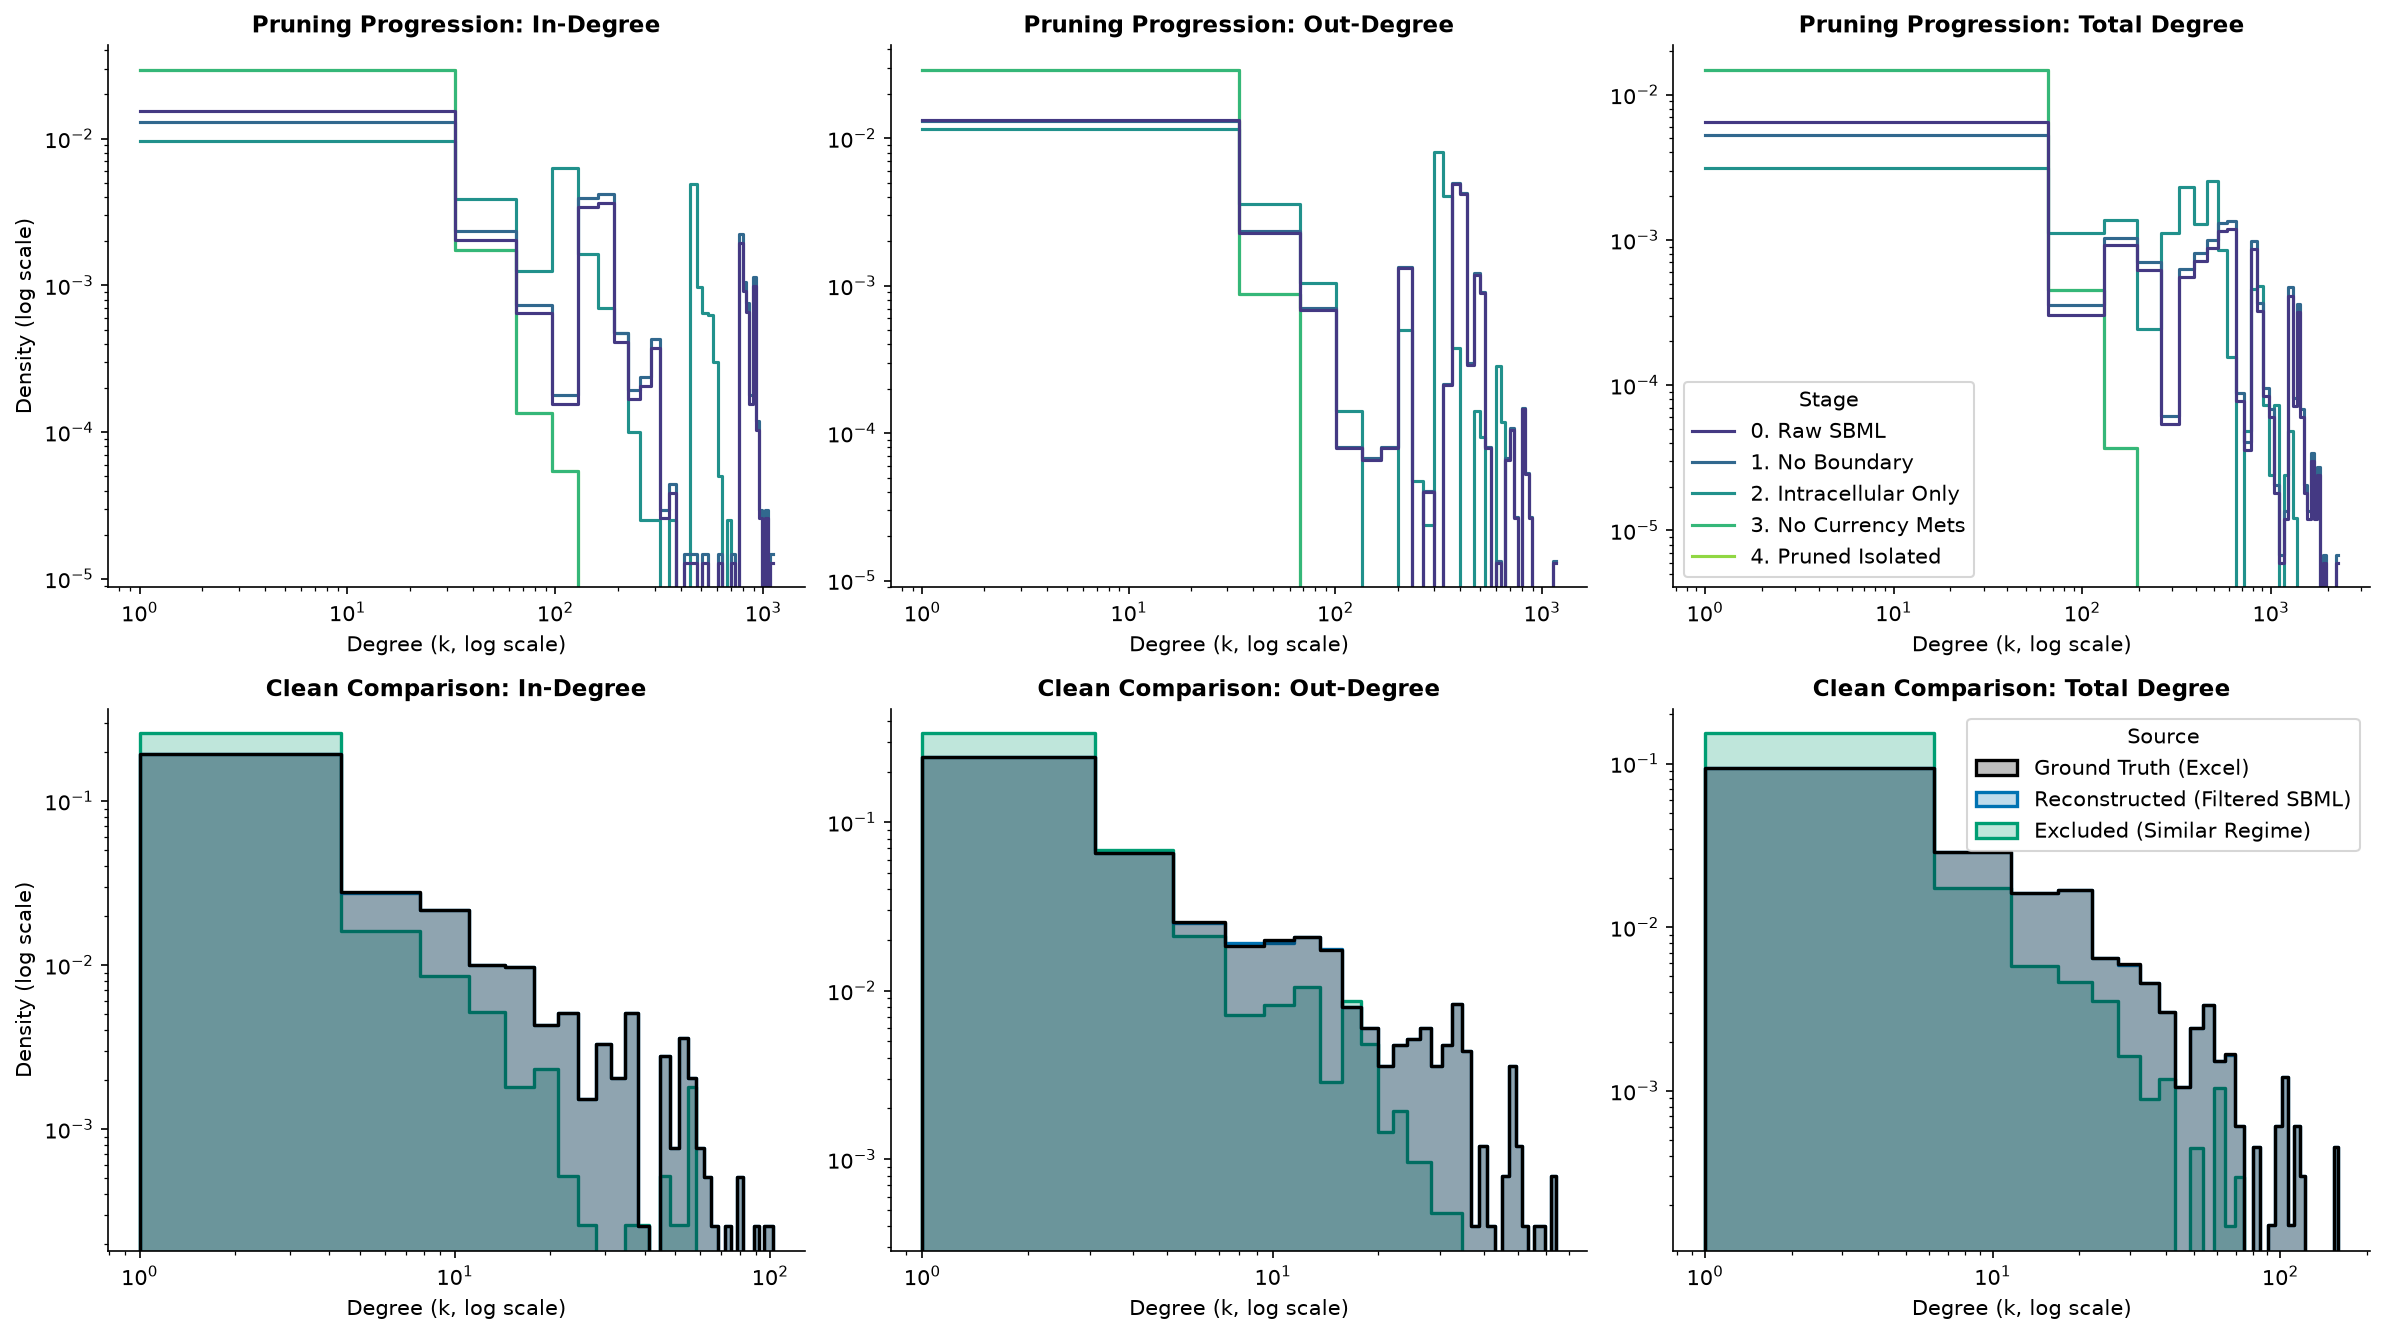

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cobra

# Default currency metabolites (strip base IDs across compartments or specific compartment IDs)
DEFAULT_CURRENCY_BASE_IDS = {
    "adp", "amp", "atp", "co2", "h2o", "h", "nad",
    "nadh", "nadp", "nadph", "nh4", "o2", "pi", "ppi"
}


def build_adj_matrix(model, rxn_ids, excluded_mets=None, match_base_id=True):
    """
    Build directed reaction-reaction adjacency matrix from a COBRA model.
    If match_base_id=True, 'atp' matches 'atp_c', 'atp_p', 'atp_m', etc.
    """
    if excluded_mets is None:
        excluded_mets = set()

    n = len(rxn_ids)
    rxn_to_idx = {rid: i for i, rid in enumerate(rxn_ids)}
    A = np.zeros((n, n), dtype=int)
    prod_by, cons_by = {}, {}

    for rid in rxn_ids:
        rxn = model.reactions.get_by_id(rid)
        for met, coeff in rxn.metabolites.items():
            base_id = met.id.rsplit("_", 1)[0] if "_" in met.id else met.id
            if met.id in excluded_mets or (match_base_id and base_id in excluded_mets):
                continue

            if coeff > 0:
                prod_by.setdefault(met.id, []).append(rid)
            elif coeff < 0:
                cons_by.setdefault(met.id, []).append(rid)

            if rxn.reversibility:
                if coeff < 0:
                    prod_by.setdefault(met.id, []).append(rid)
                elif coeff > 0:
                    cons_by.setdefault(met.id, []).append(rid)

    for met_id in set(prod_by) & set(cons_by):
        for u in prod_by[met_id]:
            for v in cons_by[met_id]:
                if u != v:
                    A[rxn_to_idx[u], rxn_to_idx[v]] = 1

    return A


def filter_metabolic_network(
    model,
    allowed_compartments=("c",),
    currency_mets=DEFAULT_CURRENCY_BASE_IDS,
    match_base_id=True,
    prune_isolated=True,
    iterative_dead_ends=False
):
    """
    Standalone reusable filtering pipeline to reconstruct clean intracellular reaction networks
    from raw SBML models.

    Steps:
      0. Raw SBML model (all reactions, all metabolites)
      1. Remove boundary reactions (EX_, DM_, SK_)
      2. Restrict to allowed intracellular compartments (e.g., ('c',) for prokaryotes, ('c', 'm') for yeast)
      3. Strip currency metabolites from edge construction
      4. Prune isolated nodes (total_degree == 0), and optionally iterative dead-ends (in=0 or out=0)

    Returns:
      dict with final 'rxn_ids', 'adj_matrix', 'degree_df', and 'steps' (snapshots at each stage).
    """
    allowed_set = set(allowed_compartments)
    steps = {}

    # Step 0: Raw full SBML
    rxns_s0 = [r.id for r in model.reactions]
    A_s0 = build_adj_matrix(model, rxns_s0, excluded_mets=set())
    steps["0. Raw SBML"] = {"rxn_ids": rxns_s0, "A": A_s0}

    # Step 1: Remove boundary reactions (EX_, DM_, SK_)
    rxns_s1 = [r.id for r in model.reactions if not r.boundary]
    A_s1 = build_adj_matrix(model, rxns_s1, excluded_mets=set())
    steps["1. No Boundary"] = {"rxn_ids": rxns_s1, "A": A_s1}

    # Step 2: Restrict to allowed intracellular compartments
    rxns_s2 = [
        r.id for r in model.reactions
        if not r.boundary and {m.compartment for m in r.metabolites}.issubset(allowed_set)
    ]
    A_s2 = build_adj_matrix(model, rxns_s2, excluded_mets=set())
    steps["2. Intracellular Only"] = {"rxn_ids": rxns_s2, "A": A_s2}

    # Step 3: Strip currency metabolites
    rxns_s3 = list(rxns_s2)
    A_s3 = build_adj_matrix(model, rxns_s3, excluded_mets=currency_mets, match_base_id=match_base_id)
    steps["3. No Currency Mets"] = {"rxn_ids": rxns_s3, "A": A_s3}

    # Step 4: Prune isolated nodes (and optionally iterative dead-ends)
    rxns_s4 = list(rxns_s3)
    A_s4 = A_s3.copy()
    if prune_isolated and len(rxns_s4) > 0:
        while True:
            in_d = A_s4.sum(axis=0)
            out_d = A_s4.sum(axis=1)
            if iterative_dead_ends:
                keep_mask = (in_d > 0) & (out_d > 0)
            else:
                keep_mask = (in_d + out_d) > 0

            if keep_mask.all():
                break
            rxns_s4 = [rid for rid, keep in zip(rxns_s4, keep_mask) if keep]
            A_s4 = A_s4[np.ix_(keep_mask, keep_mask)]
            if not iterative_dead_ends:
                break

    steps["4. Pruned Isolated"] = {"rxn_ids": rxns_s4, "A": A_s4}

    # Compute final degree table
    out_deg = A_s4.sum(axis=1)
    in_deg = A_s4.sum(axis=0)
    deg_df = pd.DataFrame({
        "rxn_id": rxns_s4,
        "in_degree": in_deg,
        "out_degree": out_deg,
        "total_degree": in_deg + out_deg
    })

    return {
        "rxn_ids": rxns_s4,
        "adj_matrix": A_s4,
        "degree_df": deg_df,
        "steps": steps
    }


def analyze_pruning_pipeline(
    model,
    gt_adj_df=None,
    allowed_compartments=("c",),
    currency_mets=DEFAULT_CURRENCY_BASE_IDS,
    match_base_id=True,
    prune_isolated=True,
    iterative_dead_ends=False
):
    """
    Runs filter_metabolic_network(), prints comprehensive step-by-step statistics and
    ground-truth comparisons (if gt_adj_df is provided), and plots:
      Row 1: Step-by-step pruning progression (In, Out, Total degree distributions across stages)
      Row 2: Final Filtered Network vs. Ground Truth & Excluded-Similar Regime comparison
    """
    res = filter_metabolic_network(
        model=model,
        allowed_compartments=allowed_compartments,
        currency_mets=currency_mets,
        match_base_id=match_base_id,
        prune_isolated=prune_isolated,
        iterative_dead_ends=iterative_dead_ends
    )
    steps = res["steps"]

    # 1. Step-by-Step Pruning Summary Table
    print("=== 1. Step-by-Step Network Pruning Progression ===")
    step_rows = []
    step_deg_records = []

    for step_name, data in steps.items():
        A = data["A"]
        rids = data["rxn_ids"]
        out_d = A.sum(axis=1)
        in_d = A.sum(axis=0)
        tot_d = in_d + out_d

        step_rows.append({
            "Stage": step_name,
            "Nodes": len(rids),
            "Edges": int(A.sum()),
            "Isolated (k=0)": int((tot_d == 0).sum()),
            "Mean_In": round(in_d.mean(), 2) if len(rids) else 0,
            "Median_In": float(np.median(in_d)) if len(rids) else 0,
            "Max_In": int(in_d.max()) if len(rids) else 0,
            "Mean_Out": round(out_d.mean(), 2) if len(rids) else 0,
            "Median_Out": float(np.median(out_d)) if len(rids) else 0,
            "Max_Out": int(out_d.max()) if len(rids) else 0,
            "Mean_Total": round(tot_d.mean(), 2) if len(rids) else 0,
            "Max_Total": int(tot_d.max()) if len(rids) else 0,
        })

        for rid, ind, outd, totd in zip(rids, in_d, out_d, tot_d):
            step_deg_records.append({
                "Stage": step_name,
                "rxn_id": rid,
                "in_degree": ind,
                "out_degree": outd,
                "total_degree": totd
            })

    step_summary_df = pd.DataFrame(step_rows)
    step_deg_df = pd.DataFrame(step_deg_records)
    print(step_summary_df.to_string(index=False))

    # 2. Ground-Truth Comparison (if gt_adj_df is supplied)
    gt_deg_df = None
    regime_df = None
    if gt_adj_df is not None:
        gt_df = gt_adj_df.copy()
        gt_df.index = gt_df.index.astype(str).str.strip()
        gt_df.columns = gt_df.columns.astype(str).str.strip()
        gt_rxns = set(gt_df.index)
        final_rxns = set(res["rxn_ids"])

        print("\n=== 2. Reaction Set Overlap: Reconstructed vs. Ground Truth ===")
        print(f"Ground-Truth Excel reactions:  {len(gt_rxns)}")
        print(f"Reconstructed reactions:       {len(final_rxns)}")
        print(f"Exact ID Overlap:              {len(gt_rxns & final_rxns)}")
        print(f"In Ground Truth ONLY:          {sorted(gt_rxns - final_rxns)}")
        print(f"In Reconstructed ONLY:         {sorted(final_rxns - gt_rxns)}")

        # Edge comparison on overlapping subgraph
        common_rxns = [r for r in gt_df.index if r in final_rxns]
        A_gt_sub = (gt_df.loc[common_rxns, common_rxns].values > 0).astype(int)
        A_rec_sub = build_adj_matrix(model, common_rxns, excluded_mets=currency_mets, match_base_id=match_base_id)
        print(f"\nOverlapping Subgraph Edges -> GT: {A_gt_sub.sum()} | Reconstructed: {A_rec_sub.sum()} "
              f"(Extra: {(A_rec_sub & ~A_gt_sub).sum()}, Missing: {(~A_rec_sub & A_gt_sub).sum()})")

        # Ground-truth full degrees
        A_gt_full = (gt_df.values > 0).astype(int)
        gt_out = A_gt_full.sum(axis=1)
        gt_in = A_gt_full.sum(axis=0)
        gt_deg_df = pd.DataFrame({
            "rxn_id": gt_df.index,
            "Source": "Ground Truth (Excel)",
            "in_degree": gt_in,
            "out_degree": gt_out,
            "total_degree": gt_in + gt_out
        })

        # Regime & Compartment analysis on full currency-cleaned SBML
        sbml_rxns = [r.id for r in model.reactions]
        A_full_clean = build_adj_matrix(model, sbml_rxns, excluded_mets=currency_mets, match_base_id=match_base_id)
        full_in = A_full_clean.sum(axis=0)
        full_out = A_full_clean.sum(axis=1)
        full_tot = full_in + full_out

        max_in, max_out = gt_in.max(), gt_out.max()
        meta_rows = []
        for idx, rid in enumerate(sbml_rxns):
            rxn = model.reactions.get_by_id(rid)
            comps = sorted({m.compartment for m in rxn.metabolites})
            status = "Included" if rid in gt_rxns else "Excluded"
            if status == "Included":
                regime = "Included (Ground Truth)"
            elif full_tot[idx] == 0:
                regime = "Excluded: Isolated (k=0)"
            elif full_in[idx] > max_in or full_out[idx] > max_out:
                regime = "Excluded: High-Degree Hubs"
            else:
                regime = "Excluded: Similar Distribution"

            meta_rows.append({
                "rxn_id": rid,
                "status": status,
                "regime": regime,
                "compartments": "_".join(comps),
                "is_allowed_comp": set(comps).issubset(set(allowed_compartments)),
                "is_boundary": rxn.boundary,
                "is_transport": len(comps) > 1,
                "in_degree": full_in[idx],
                "out_degree": full_out[idx],
                "total_degree": full_tot[idx]
            })
        regime_df = pd.DataFrame(meta_rows)

        print("\n=== 3. Excluded Reactions Breakdown by Degree Regime (Full Clean SBML) ===")
        regime_summary = regime_df.groupby("regime").agg(
            Count=("rxn_id", "count"),
            Allowed_Comp=("is_allowed_comp", "sum"),
            MultiComp_Transport=("is_transport", "sum"),
            Boundary=("is_boundary", "sum"),
            Mean_In=("in_degree", lambda x: round(x.mean(), 2)),
            Median_In=("in_degree", "median"),
            Mean_Out=("out_degree", lambda x: round(x.mean(), 2)),
            Median_Out=("out_degree", "median"),
            Mean_Tot=("total_degree", lambda x: round(x.mean(), 2)),
            Median_Tot=("total_degree", "median"),
        )
        print(regime_summary.to_string())

    # 3. Plotting: Step-by-Step Progression (Top Row) & Final vs. Ground Truth (Bottom Row)
    n_rows = 2 if gt_deg_df is not None else 1
    fig, axes = plt.subplots(n_rows, 3, figsize=(16, 4.5 * n_rows), dpi=150)
    if n_rows == 1:
        axes = np.expand_dims(axes, axis=0)

    metrics = [("in_degree", "In-Degree"), ("out_degree", "Out-Degree"), ("total_degree", "Total Degree")]

    # Row 0: Step-by-step pruning progression
    stage_palette = sns.color_palette("viridis", n_colors=len(steps))
    for ax, (col, title) in zip(axes[0], metrics):
        sns.histplot(
            data=step_deg_df[step_deg_df[col] > 0],
            x=col,
            hue="Stage",
            palette=stage_palette,
            bins=35,
            stat="density",
            common_norm=False,
            element="step",
            fill=False,
            linewidth=1.5,
            ax=ax
        )
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(f"Pruning Progression: {title}", fontsize=11, fontweight="bold")
        ax.set_xlabel("Degree (k, log scale)", fontsize=10)
        ax.set_ylabel("Density (log scale)" if ax == axes[0, 0] else "", fontsize=10)
        if ax != axes[0, 2]:
            ax.get_legend().remove()
        sns.despine(ax=ax)

    # Row 1: Reconstructed Final vs. Ground Truth vs. Excluded (Similar Regime)
    if gt_deg_df is not None:
        rec_plot = res["degree_df"].copy()
        rec_plot["Source"] = "Reconstructed (Filtered SBML)"
        excl_sim_plot = regime_df[regime_df["regime"] == "Excluded: Similar Distribution"][
            ["rxn_id", "in_degree", "out_degree", "total_degree"]
        ].copy()
        excl_sim_plot["Source"] = "Excluded (Similar Regime)"

        comp_plot_df = pd.concat([gt_deg_df, rec_plot, excl_sim_plot], ignore_index=True)
        comp_palette = {
            "Ground Truth (Excel)": "#000000",
            "Reconstructed (Filtered SBML)": "#0072B2",
            "Excluded (Similar Regime)": "#009E73"
        }

        for ax, (col, title) in zip(axes[1], metrics):
            sns.histplot(
                data=comp_plot_df[comp_plot_df[col] > 0],
                x=col,
                hue="Source",
                palette=comp_palette,
                bins=30,
                stat="density",
                common_norm=False,
                element="step",
                alpha=0.25,
                linewidth=1.6,
                ax=ax
            )
            ax.set_xscale("log")
            ax.set_yscale("log")
            ax.set_title(f"Clean Comparison: {title}", fontsize=11, fontweight="bold")
            ax.set_xlabel("Degree (k, log scale)", fontsize=10)
            ax.set_ylabel("Density (log scale)" if ax == axes[1, 0] else "", fontsize=10)
            if ax != axes[1, 2]:
                ax.get_legend().remove()
            sns.despine(ax=ax)

    plt.tight_layout()
    plt.show()

    return {
        "filter_result": res,
        "step_summary": step_summary_df,
        "step_degrees": step_deg_df,
        "regime_df": regime_df
    }
# 1. Load model and ground-truth Excel sheet
bigg_file_old = "/mnt/c/Users/loren/Downloads/iJO1366.xml.gz"
model_old = cobra.io.read_sbml_model(bigg_file_old)
adj_df = pd.read_excel(excel_path, sheet_name="E.coli (iJ01366)", index_col=0)

# 2. Run full diagnostic comparison and visualization
report_old = analyze_pruning_pipeline(
    model=model_old,
    gt_adj_df=adj_df,
    allowed_compartments=("c",),
    prune_isolated=True,
    iterative_dead_ends=False
)
filtered_ecoli = filter_metabolic_network(model_old, allowed_compartments=("c",))
A_clean_ecoli = filtered_ecoli["adj_matrix"]
rxn_ids_ecoli = filtered_ecoli["rxn_ids"]
deg_table_ecoli = filtered_ecoli["degree_df"]


# no boundary: Removes  artificial system-boundary reactions (EX_ exchange, DM_ demand, and SK_ sink reactions)
# intracellular only: Strips out  extracellular (_e), periplasmic (_p), and cross-membrane transport reactions, leaving strictly cytosolic (_c) reactions.
# no currency mets: Removes the 14 currency metabolites (h_c, h2o_c, atp_c, nad_c, etc.)
# pruned Isolated: removes reactions with no edges




# For eukaryotic models like S. cerevisiae (iMM904), include both cytosol ('c') and mitochondria ('m'):
# filtered_yeast = filter_metabolic_network(model_yeast, allowed_compartments=("c", "m"))

=== Multi-Organism QC: Old BiGG Reconstruction vs. Paper Ground Truth ===
          Organism   Model           File  GT_Nodes  BiGG_Nodes  Node_Overlap  GT_Edges  BiGG_Edges  Subgraph_Extra  Subgraph_Missing gamma_tot (GT / BiGG) gamma_in (GT / BiGG) gamma_out (GT / BiGG)
           E. coli iJO1366 iJO1366.xml.gz      1251        1253          1243      9099        9086               0                 0         -1.29 / -1.30        -1.32 / -1.31         -1.50 / -1.50
       B. subtilis  iYO844  iYO844.xml.gz       748         742           741      6489        6559               0                 0         -1.04 / -1.02        -1.10 / -1.09         -1.12 / -1.15
G. metallireducens  iAF987  iAF987.xml.gz       900         860           857      8049        7193               0                 0         -1.04 / -1.03        -1.14 / -1.17         -1.12 / -1.16
     K. pneumoniae iYL1228 iYL1228.xml.gz      1137        1114          1079      8084        7738               3               

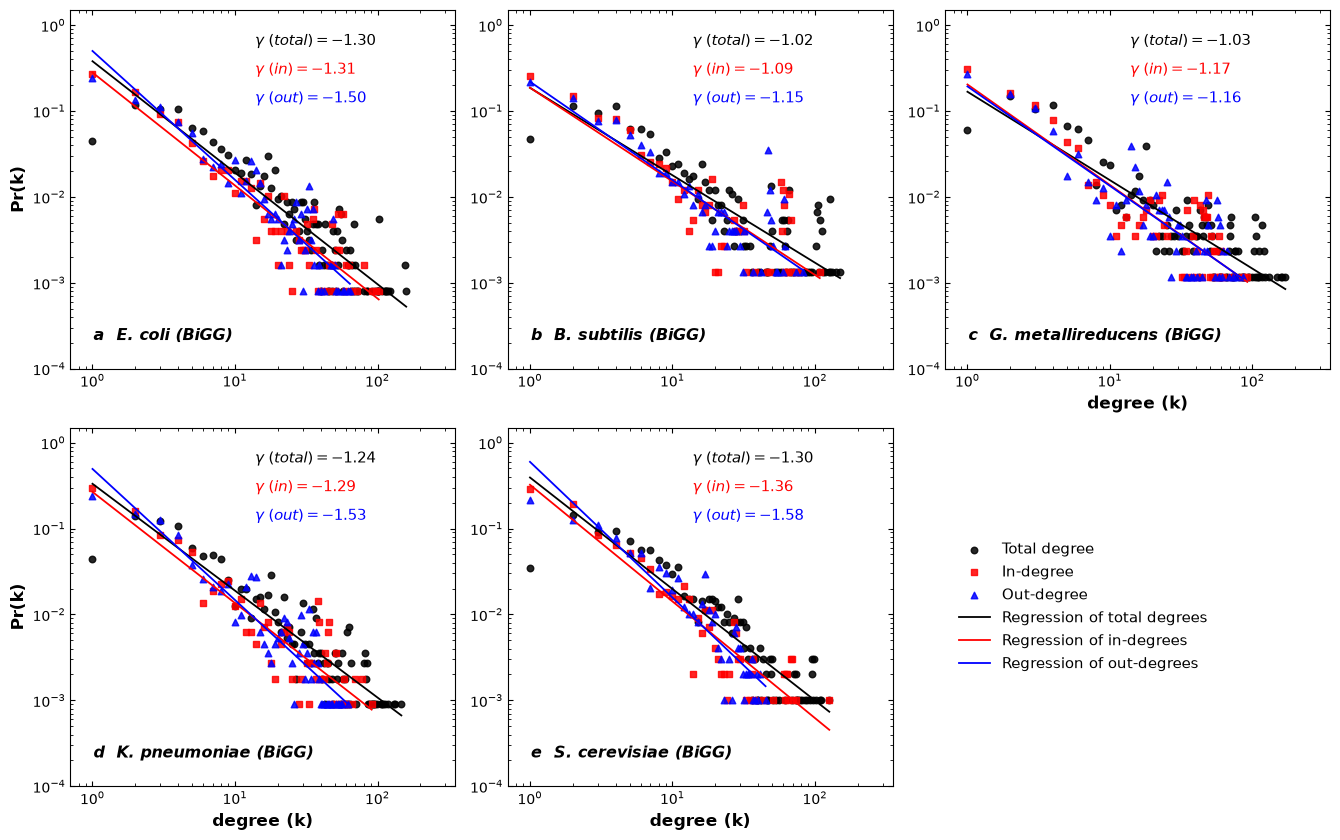

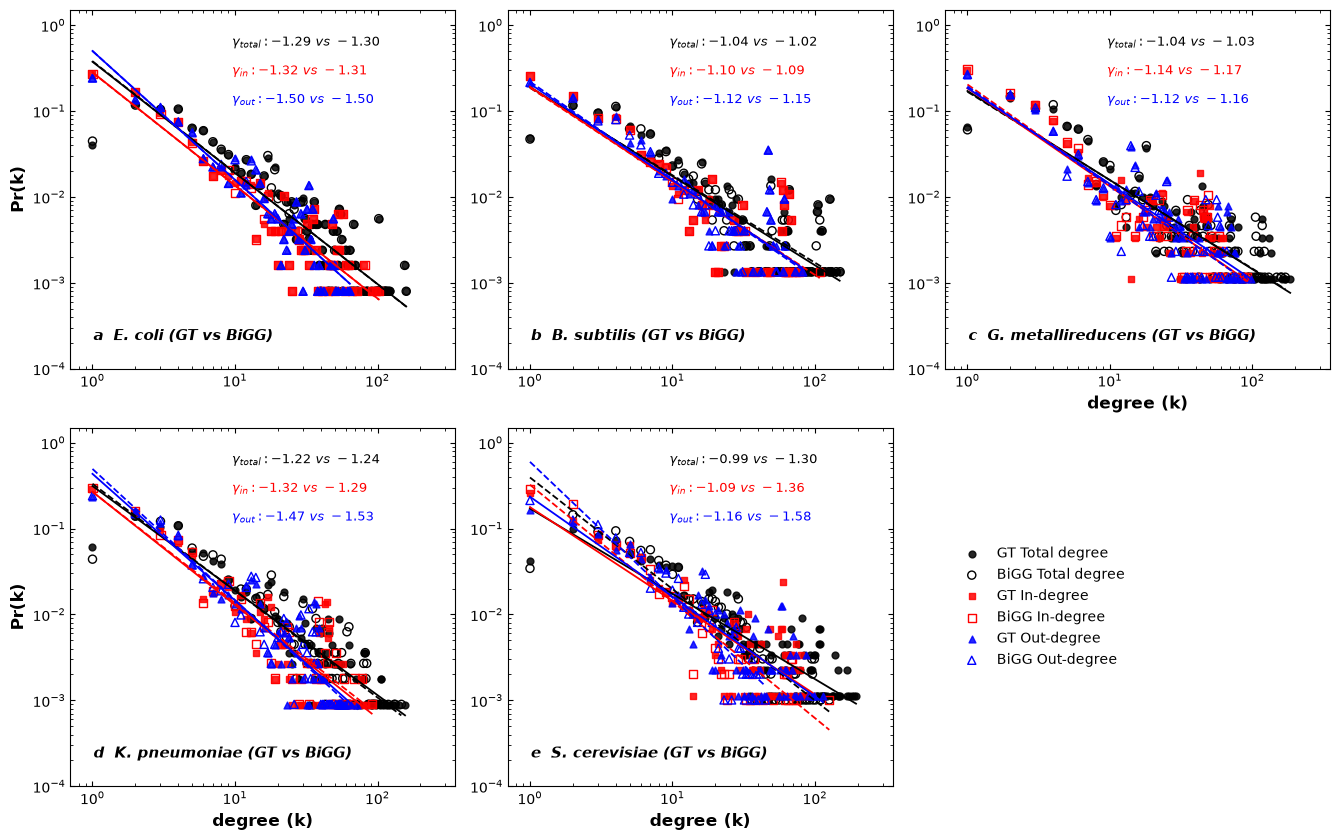

In [26]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cobra

# 1. Paths and Organism Configuration
bigg_dir = "/mnt/c/Users/loren/Downloads/old_bigg"
excel_path = "/mnt/c/Users/loren/Downloads/data-20261116T170559Z-1-001/data/12859_2019_2897_MOESM2_ESM.xlsx"
xl = pd.ExcelFile(excel_path)

organisms = [
    {"panel": "a", "label": "E. coli",            "model_id": "iJO1366", "keywords": ["coli", "1366"],          "compartments": ("c",)},
    {"panel": "b", "label": "B. subtilis",        "model_id": "iYO844",  "keywords": ["subtilis", "844"],       "compartments": ("c",)},
    {"panel": "c", "label": "G. metallireducens", "model_id": "iAF987",  "keywords": ["metallireducens", "987"],"compartments": ("c",)},
    {"panel": "d", "label": "K. pneumoniae",      "model_id": "iYL1228", "keywords": ["pneumoniae", "1228"],    "compartments": ("c",)},
    {"panel": "e", "label": "S. cerevisiae",      "model_id": "iMM904",  "keywords": ["cerevisiae", "904"],     "compartments": ("c", "m")},
]

DEFAULT_CURRENCY_BASE_IDS = {
    "adp", "amp", "atp", "co2", "h2o", "h", "nad",
    "nadh", "nadp", "nadph", "nh4", "o2", "pi", "ppi"
}


def find_and_load_bigg_model(directory, model_id):
    """Locate and load an SBML or JSON BiGG model matching model_id in directory."""
    patterns = [f"*{model_id}*.xml.gz", f"*{model_id}*.xml", f"*{model_id}*.sbml", f"*{model_id}*.json",f"*{model_id}*.biggr.sbml.gz"]
    matches = []
    for pat in patterns:
        matches.extend(glob.glob(os.path.join(directory, pat)))
    if not matches:
        raise FileNotFoundError(f"No model file matching '{model_id}' found in {directory}")
    filepath = sorted(matches)[0]
    if filepath.endswith(".json"):
        return cobra.io.load_json_model(filepath), filepath
    return cobra.io.read_sbml_model(filepath), filepath


def match_sheet(sheet_names, keywords, fallback_idx):
    for s in sheet_names:
        if any(kw in s.lower() for kw in keywords):
            return s
    return sheet_names[fallback_idx]


def build_adj_matrix(model, rxn_ids, excluded_mets=DEFAULT_CURRENCY_BASE_IDS, match_base_id=True):
    n = len(rxn_ids)
    rxn_to_idx = {rid: i for i, rid in enumerate(rxn_ids)}
    A = np.zeros((n, n), dtype=int)
    prod_by, cons_by = {}, {}

    for rid in rxn_ids:
        rxn = model.reactions.get_by_id(rid)
        for met, coeff in rxn.metabolites.items():
            base_id = met.id.rsplit("_", 1)[0] if "_" in met.id else met.id
            if met.id in excluded_mets or (match_base_id and base_id in excluded_mets):
                continue
            if coeff > 0:
                prod_by.setdefault(met.id, []).append(rid)
            elif coeff < 0:
                cons_by.setdefault(met.id, []).append(rid)

            if rxn.reversibility:
                if coeff < 0:
                    prod_by.setdefault(met.id, []).append(rid)
                elif coeff > 0:
                    cons_by.setdefault(met.id, []).append(rid)

    for met_id in set(prod_by) & set(cons_by):
        for u in prod_by[met_id]:
            for v in cons_by[met_id]:
                if u != v:
                    A[rxn_to_idx[u], rxn_to_idx[v]] = 1
    return A


def filter_metabolic_network(model, allowed_compartments=("c",), currency_mets=DEFAULT_CURRENCY_BASE_IDS):
    allowed_set = set(allowed_compartments)
    rxns_s2 = [
        r.id for r in model.reactions
        if not r.boundary and {m.compartment for m in r.metabolites}.issubset(allowed_set)
    ]
    A_s3 = build_adj_matrix(model, rxns_s2, excluded_mets=currency_mets, match_base_id=True)
    keep_mask = (A_s3.sum(axis=0) + A_s3.sum(axis=1)) > 0
    rxns_final = [rid for rid, keep in zip(rxns_s2, keep_mask) if keep]
    A_final = A_s3[np.ix_(keep_mask, keep_mask)]
    return rxns_final, A_final


def compute_degree_distribution(deg_array):
    n_nodes = len(deg_array)
    pos_deg = deg_array[deg_array > 0]
    unique_k, counts = np.unique(pos_deg, return_counts=True)
    prob_k = counts / float(n_nodes)
    return unique_k, prob_k


def fit_gamma(deg_array):
    k_vals, pr_vals = compute_degree_distribution(deg_array)
    gamma, intercept = np.polyfit(np.log10(k_vals), np.log10(pr_vals), 1)
    return k_vals, pr_vals, gamma, intercept


# 2. Run Multi-Organism Reconstruction & QC Comparison
qc_rows = []
results_cache = {}

for idx, org in enumerate(organisms):
    # Load old BiGG SBML
    model, fpath = find_and_load_bigg_model(bigg_dir, org["model_id"])
    rec_rxns, A_rec = filter_metabolic_network(model, allowed_compartments=org["compartments"])
    rec_set = set(rec_rxns)

    # Load Ground-Truth Excel
    sheet_name = match_sheet(xl.sheet_names, org["keywords"], idx)
    adj_df = pd.read_excel(excel_path, sheet_name=sheet_name, index_col=0)
    adj_df.index = adj_df.index.astype(str).str.strip()
    adj_df.columns = adj_df.columns.astype(str).str.strip()
    common_idx = adj_df.index.intersection(adj_df.columns)
    adj_df = adj_df.loc[common_idx, common_idx]
    A_gt = (adj_df.values > 0).astype(int)
    gt_set = set(adj_df.index)

    # Subgraph edge comparison on shared reactions
    shared_rxns = [r for r in adj_df.index if r in rec_set]
    A_gt_sub = (adj_df.loc[shared_rxns, shared_rxns].values > 0).astype(int)
    A_rec_sub = build_adj_matrix(model, shared_rxns)
    extra_edges = int((A_rec_sub & ~A_gt_sub).sum())
    missing_edges = int((~A_rec_sub & A_gt_sub).sum())

    # Degree distributions & exponents
    rec_out, rec_in = A_rec.sum(axis=1), A_rec.sum(axis=0)
    rec_tot = rec_in + rec_out
    gt_out, gt_in = A_gt.sum(axis=1), A_gt.sum(axis=0)
    gt_tot = gt_in + gt_out

    _, _, g_rec_tot, _ = fit_gamma(rec_tot)
    _, _, g_rec_in, _ = fit_gamma(rec_in)
    _, _, g_rec_out, _ = fit_gamma(rec_out)

    _, _, g_gt_tot, _ = fit_gamma(gt_tot)
    _, _, g_gt_in, _ = fit_gamma(gt_in)
    _, _, g_gt_out, _ = fit_gamma(gt_out)

    qc_rows.append({
        "Organism": org["label"],
        "Model": org["model_id"],
        "File": os.path.basename(fpath),
        "GT_Nodes": len(gt_set),
        "BiGG_Nodes": len(rec_set),
        "Node_Overlap": len(gt_set & rec_set),
        "GT_Edges": int(A_gt.sum()),
        "BiGG_Edges": int(A_rec.sum()),
        "Subgraph_Extra": extra_edges,
        "Subgraph_Missing": missing_edges,
        "gamma_tot (GT / BiGG)": f"{g_gt_tot:.2f} / {g_rec_tot:.2f}",
        "gamma_in (GT / BiGG)": f"{g_gt_in:.2f} / {g_rec_in:.2f}",
        "gamma_out (GT / BiGG)": f"{g_gt_out:.2f} / {g_rec_out:.2f}",
    })

    results_cache[org["model_id"]] = {
        "org": org,
        "gt_only": sorted(gt_set - rec_set),
        "rec_only": sorted(rec_set - gt_set),
        "rec_deg": {"total": rec_tot, "in": rec_in, "out": rec_out},
        "gt_deg": {"total": gt_tot, "in": gt_in, "out": gt_out},
    }

qc_df = pd.DataFrame(qc_rows)
print("=== Multi-Organism QC: Old BiGG Reconstruction vs. Paper Ground Truth ===")
print(qc_df.to_string(index=False))

print("\n=== Node Discrepancies Detail per Organism ===")
for mid, data in results_cache.items():
    print(f"\n[{data['org']['label']} ({mid})]")
    print(f"  In GT ONLY ({len(data['gt_only'])}):   {data['gt_only'][:15]}{'...' if len(data['gt_only']) > 15 else ''}")
    print(f"  In BiGG ONLY ({len(data['rec_only'])}): {data['rec_only'][:15]}{'...' if len(data['rec_only']) > 15 else ''}")


# 3. Plot Figure 2 Recreated Strictly from Old BiGG Files
series_styles = [
    {"key": "total", "label": "Total degree", "reg_label": "Regression of total degrees", "color": "black", "marker": "o", "y_text": 0.90},
    {"key": "in",    "label": "In-degree",    "reg_label": "Regression of in-degrees",    "color": "red",   "marker": "s", "y_text": 0.82},
    {"key": "out",   "label": "Out-degree",   "reg_label": "Regression of out-degrees",   "color": "blue",  "marker": "^", "y_text": 0.74},
]

fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.5))
axes_flat = axes.flatten()
panel_axes, legend_ax = axes_flat[:5], axes_flat[5]

for idx, (org, ax) in enumerate(zip(organisms, panel_axes)):
    deg_dict = results_cache[org["model_id"]]["rec_deg"]
    for style in series_styles:
        k_vals, pr_vals, gamma, intercept = fit_gamma(deg_dict[style["key"]])
        ax.scatter(k_vals, pr_vals, color=style["color"], marker=style["marker"], s=22, alpha=0.85, label=style["label"])
        k_line = np.logspace(np.log10(k_vals.min()), np.log10(k_vals.max()), 100)
        pr_line = (10 ** intercept) * (k_line ** gamma)
        ax.plot(k_line, pr_line, color=style["color"], linewidth=1.3, label=style["reg_label"])
        ax.text(0.48, style["y_text"], rf"$\gamma\ ({style['key']}) = {gamma:.2f}$",
                transform=ax.transAxes, color=style["color"], fontsize=10.5, fontweight="bold")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.7, 350)
    ax.set_ylim(3e-4, 1.5)
    ax.set_xticks([1, 10, 100])
    ax.set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1e0])
    ax.tick_params(axis="both", which="major", labelsize=10, direction="in", top=True, right=True)
    ax.tick_params(axis="both", which="minor", direction="in", top=True, right=True)
    ax.text(0.06, 0.08, f"{org['panel']}  {org['label']} (BiGG)", transform=ax.transAxes, fontsize=11.5, fontweight="bold", style="italic")
    if idx in [0, 3]:
        ax.set_ylabel("Pr(k)", fontsize=12, fontweight="bold")
    if idx in [2, 3, 4]:
        ax.set_xlabel("degree (k)", fontsize=12, fontweight="bold")

legend_ax.axis("off")
handles, labels = panel_axes[0].get_legend_handles_labels()
order = [0, 2, 4, 1, 3, 5]
legend_ax.legend([handles[i] for i in order], [labels[i] for i in order], loc="center left", frameon=False, fontsize=11)
plt.tight_layout()
plt.savefig("figure2_reconstructed_from_bigg.png", dpi=300)
plt.show()


# 4. Side-by-Side QC Overlay: Ground Truth (Solid) vs. BiGG Reconstruction (Open / Dashed)
fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.5))
axes_flat = axes.flatten()
panel_axes, legend_ax = axes_flat[:5], axes_flat[5]

for idx, (org, ax) in enumerate(zip(organisms, panel_axes)):
    gt_deg = results_cache[org["model_id"]]["gt_deg"]
    rec_deg = results_cache[org["model_id"]]["rec_deg"]

    for style in series_styles:
        # Ground Truth (solid markers & solid line)
        k_gt, pr_gt, g_gt, int_gt = fit_gamma(gt_deg[style["key"]])
        ax.scatter(k_gt, pr_gt, color=style["color"], marker=style["marker"], s=24, alpha=0.85,
                   label=f"GT {style['label']}")
        k_line_gt = np.logspace(np.log10(k_gt.min()), np.log10(k_gt.max()), 100)
        ax.plot(k_line_gt, (10 ** int_gt) * (k_line_gt ** g_gt), color=style["color"], linewidth=1.3)

        # BiGG Reconstruction (open markers & dashed line)
        k_rec, pr_rec, g_rec, int_rec = fit_gamma(rec_deg[style["key"]])
        ax.scatter(k_rec, pr_rec, facecolors="none", edgecolors=style["color"], marker=style["marker"], s=34, linewidth=1.0,
                   label=f"BiGG {style['label']}")
        k_line_rec = np.logspace(np.log10(k_rec.min()), np.log10(k_rec.max()), 100)
        ax.plot(k_line_rec, (10 ** int_rec) * (k_line_rec ** g_rec), color=style["color"], linewidth=1.3, linestyle="--")

        ax.text(0.42, style["y_text"], rf"$\gamma_{{{style['key']}}}: {g_gt:.2f}\ vs\ {g_rec:.2f}$",
                transform=ax.transAxes, color=style["color"], fontsize=9.5, fontweight="bold")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.7, 350)
    ax.set_ylim(3e-4, 1.5)
    ax.set_xticks([1, 10, 100])
    ax.set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1e0])
    ax.tick_params(axis="both", which="major", labelsize=10, direction="in", top=True, right=True)
    ax.tick_params(axis="both", which="minor", direction="in", top=True, right=True)
    ax.text(0.06, 0.08, f"{org['panel']}  {org['label']} (GT vs BiGG)", transform=ax.transAxes, fontsize=11, fontweight="bold", style="italic")
    if idx in [0, 3]:
        ax.set_ylabel("Pr(k)", fontsize=12, fontweight="bold")
    if idx in [2, 3, 4]:
        ax.set_xlabel("degree (k)", fontsize=12, fontweight="bold")

legend_ax.axis("off")
handles, labels = panel_axes[0].get_legend_handles_labels()
legend_ax.legend(handles, labels, loc="center left", frameon=False, fontsize=10)
plt.tight_layout()
plt.savefig("figure2_qc_overlay_bigg_vs_excel.png", dpi=300)
plt.show()

# With new files instead

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cobra

# 1. Paths and Organism Configuration
bigg_dir = "/mnt/c/Users/loren/Downloads/data-20261116T170559Z-1-001/data"
excel_path = "/mnt/c/Users/loren/Downloads/data-20261116T170559Z-1-001/data/12859_2019_2897_MOESM2_ESM.xlsx"
xl = pd.ExcelFile(excel_path)

organisms = [
    {"panel": "a", "label": "E. coli",            "model_id": "iJO1366", "keywords": ["coli", "1366"],          "compartments": ("c",)},
    {"panel": "b", "label": "B. subtilis",        "model_id": "iYO844",  "keywords": ["subtilis", "844"],       "compartments": ("c",)},
    {"panel": "c", "label": "G. metallireducens", "model_id": "iAF987",  "keywords": ["metallireducens", "987"],"compartments": ("c",)},
    {"panel": "d", "label": "K. pneumoniae",      "model_id": "iYL1228", "keywords": ["pneumoniae", "1228"],    "compartments": ("c",)},
    {"panel": "e", "label": "S. cerevisiae",      "model_id": "iMM904",  "keywords": ["cerevisiae", "904"],     "compartments": ("c", "m")},
]

DEFAULT_CURRENCY_BASE_IDS = {
    "adp", "amp", "atp", "co2", "h2o", "h", "nad",
    "nadh", "nadp", "nadph", "nh4", "o2", "pi", "ppi"
}

# 2. Run Multi-Organism Reconstruction & QC Comparison
qc_rows = []
results_cache = {}

for idx, org in enumerate(organisms):
    # Load old BiGG SBML
    model, fpath = find_and_load_bigg_model(bigg_dir, org["model_id"])
    rec_rxns, A_rec = filter_metabolic_network(model, allowed_compartments=org["compartments"])
    rec_set = set(rec_rxns)

    # Load Ground-Truth Excel
    sheet_name = match_sheet(xl.sheet_names, org["keywords"], idx)
    adj_df = pd.read_excel(excel_path, sheet_name=sheet_name, index_col=0)
    adj_df.index = adj_df.index.astype(str).str.strip()
    adj_df.columns = adj_df.columns.astype(str).str.strip()
    common_idx = adj_df.index.intersection(adj_df.columns)
    adj_df = adj_df.loc[common_idx, common_idx]
    A_gt = (adj_df.values > 0).astype(int)
    gt_set = set(adj_df.index)

    # Subgraph edge comparison on shared reactions
    shared_rxns = [r for r in adj_df.index if r in rec_set]
    A_gt_sub = (adj_df.loc[shared_rxns, shared_rxns].values > 0).astype(int)
    A_rec_sub = build_adj_matrix(model, shared_rxns)
    extra_edges = int((A_rec_sub & ~A_gt_sub).sum())
    missing_edges = int((~A_rec_sub & A_gt_sub).sum())

    # Degree distributions & exponents
    rec_out, rec_in = A_rec.sum(axis=1), A_rec.sum(axis=0)
    rec_tot = rec_in + rec_out
    gt_out, gt_in = A_gt.sum(axis=1), A_gt.sum(axis=0)
    gt_tot = gt_in + gt_out

    _, _, g_rec_tot, _ = fit_gamma(rec_tot)
    _, _, g_rec_in, _ = fit_gamma(rec_in)
    _, _, g_rec_out, _ = fit_gamma(rec_out)

    _, _, g_gt_tot, _ = fit_gamma(gt_tot)
    _, _, g_gt_in, _ = fit_gamma(gt_in)
    _, _, g_gt_out, _ = fit_gamma(gt_out)

    qc_rows.append({
        "Organism": org["label"],
        "Model": org["model_id"],
        "File": os.path.basename(fpath),
        "GT_Nodes": len(gt_set),
        "BiGG_Nodes": len(rec_set),
        "Node_Overlap": len(gt_set & rec_set),
        "GT_Edges": int(A_gt.sum()),
        "BiGG_Edges": int(A_rec.sum()),
        "Subgraph_Extra": extra_edges,
        "Subgraph_Missing": missing_edges,
        "gamma_tot (GT / BiGG)": f"{g_gt_tot:.2f} / {g_rec_tot:.2f}",
        "gamma_in (GT / BiGG)": f"{g_gt_in:.2f} / {g_rec_in:.2f}",
        "gamma_out (GT / BiGG)": f"{g_gt_out:.2f} / {g_rec_out:.2f}",
    })

    results_cache[org["model_id"]] = {
        "org": org,
        "gt_only": sorted(gt_set - rec_set),
        "rec_only": sorted(rec_set - gt_set),
        "rec_deg": {"total": rec_tot, "in": rec_in, "out": rec_out},
        "gt_deg": {"total": gt_tot, "in": gt_in, "out": gt_out},
    }

qc_df = pd.DataFrame(qc_rows)
print("=== Multi-Organism QC: Old BiGG Reconstruction vs. Paper Ground Truth ===")
print(qc_df.to_string(index=False))

print("\n=== Node Discrepancies Detail per Organism ===")
for mid, data in results_cache.items():
    print(f"\n[{data['org']['label']} ({mid})]")
    print(f"  In GT ONLY ({len(data['gt_only'])}):   {data['gt_only'][:15]}{'...' if len(data['gt_only']) > 15 else ''}")
    print(f"  In BiGG ONLY ({len(data['rec_only'])}): {data['rec_only'][:15]}{'...' if len(data['rec_only']) > 15 else ''}")


# 3. Plot Figure 2 Recreated Strictly from Old BiGG Files
series_styles = [
    {"key": "total", "label": "Total degree", "reg_label": "Regression of total degrees", "color": "black", "marker": "o", "y_text": 0.90},
    {"key": "in",    "label": "In-degree",    "reg_label": "Regression of in-degrees",    "color": "red",   "marker": "s", "y_text": 0.82},
    {"key": "out",   "label": "Out-degree",   "reg_label": "Regression of out-degrees",   "color": "blue",  "marker": "^", "y_text": 0.74},
]

fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.5))
axes_flat = axes.flatten()
panel_axes, legend_ax = axes_flat[:5], axes_flat[5]

for idx, (org, ax) in enumerate(zip(organisms, panel_axes)):
    deg_dict = results_cache[org["model_id"]]["rec_deg"]
    for style in series_styles:
        k_vals, pr_vals, gamma, intercept = fit_gamma(deg_dict[style["key"]])
        ax.scatter(k_vals, pr_vals, color=style["color"], marker=style["marker"], s=22, alpha=0.85, label=style["label"])
        k_line = np.logspace(np.log10(k_vals.min()), np.log10(k_vals.max()), 100)
        pr_line = (10 ** intercept) * (k_line ** gamma)
        ax.plot(k_line, pr_line, color=style["color"], linewidth=1.3, label=style["reg_label"])
        ax.text(0.48, style["y_text"], rf"$\gamma\ ({style['key']}) = {gamma:.2f}$",
                transform=ax.transAxes, color=style["color"], fontsize=10.5, fontweight="bold")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.7, 350)
    ax.set_ylim(3e-4, 1.5)
    ax.set_xticks([1, 10, 100])
    ax.set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1e0])
    ax.tick_params(axis="both", which="major", labelsize=10, direction="in", top=True, right=True)
    ax.tick_params(axis="both", which="minor", direction="in", top=True, right=True)
    ax.text(0.06, 0.08, f"{org['panel']}  {org['label']} (BiGG)", transform=ax.transAxes, fontsize=11.5, fontweight="bold", style="italic")
    if idx in [0, 3]:
        ax.set_ylabel("Pr(k)", fontsize=12, fontweight="bold")
    if idx in [2, 3, 4]:
        ax.set_xlabel("degree (k)", fontsize=12, fontweight="bold")

legend_ax.axis("off")
handles, labels = panel_axes[0].get_legend_handles_labels()
order = [0, 2, 4, 1, 3, 5]
legend_ax.legend([handles[i] for i in order], [labels[i] for i in order], loc="center left", frameon=False, fontsize=11)
plt.tight_layout()
plt.savefig("figure2_reconstructed_from_bigg.png", dpi=300)
plt.show()


# 4. Side-by-Side QC Overlay: Ground Truth (Solid) vs. BiGG Reconstruction (Open / Dashed)
fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.5))
axes_flat = axes.flatten()
panel_axes, legend_ax = axes_flat[:5], axes_flat[5]

for idx, (org, ax) in enumerate(zip(organisms, panel_axes)):
    gt_deg = results_cache[org["model_id"]]["gt_deg"]
    rec_deg = results_cache[org["model_id"]]["rec_deg"]

    for style in series_styles:
        # Ground Truth (solid markers & solid line)
        k_gt, pr_gt, g_gt, int_gt = fit_gamma(gt_deg[style["key"]])
        ax.scatter(k_gt, pr_gt, color=style["color"], marker=style["marker"], s=24, alpha=0.85,
                   label=f"GT {style['label']}")
        k_line_gt = np.logspace(np.log10(k_gt.min()), np.log10(k_gt.max()), 100)
        ax.plot(k_line_gt, (10 ** int_gt) * (k_line_gt ** g_gt), color=style["color"], linewidth=1.3)

        # BiGG Reconstruction (open markers & dashed line)
        k_rec, pr_rec, g_rec, int_rec = fit_gamma(rec_deg[style["key"]])
        ax.scatter(k_rec, pr_rec, facecolors="none", edgecolors=style["color"], marker=style["marker"], s=34, linewidth=1.0,
                   label=f"BiGG {style['label']}")
        k_line_rec = np.logspace(np.log10(k_rec.min()), np.log10(k_rec.max()), 100)
        ax.plot(k_line_rec, (10 ** int_rec) * (k_line_rec ** g_rec), color=style["color"], linewidth=1.3, linestyle="--")

        ax.text(0.42, style["y_text"], rf"$\gamma_{{{style['key']}}}: {g_gt:.2f}\ vs\ {g_rec:.2f}$",
                transform=ax.transAxes, color=style["color"], fontsize=9.5, fontweight="bold")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.7, 350)
    ax.set_ylim(3e-4, 1.5)
    ax.set_xticks([1, 10, 100])
    ax.set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1e0])
    ax.tick_params(axis="both", which="major", labelsize=10, direction="in", top=True, right=True)
    ax.tick_params(axis="both", which="minor", direction="in", top=True, right=True)
    ax.text(0.06, 0.08, f"{org['panel']}  {org['label']} (GT vs BiGG)", transform=ax.transAxes, fontsize=11, fontweight="bold", style="italic")
    if idx in [0, 3]:
        ax.set_ylabel("Pr(k)", fontsize=12, fontweight="bold")
    if idx in [2, 3, 4]:
        ax.set_xlabel("degree (k)", fontsize=12, fontweight="bold")

legend_ax.axis("off")
handles, labels = panel_axes[0].get_legend_handles_labels()
legend_ax.legend(handles, labels, loc="center left", frameon=False, fontsize=10)
plt.tight_layout()
plt.savefig("figure2_qc_overlay_bigg_vs_excel.png", dpi=300)
plt.show()